In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "raw"
OUTPUT_DIR = ROOT / "data" / "processed"
PLOT_DIR = ROOT / "visualizations" / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Dataset exists:", DATA_DIR.exists())


Project root: C:\Users\S SHREYAS KUMAR\Downloads\ML_HACKATHON\PathSnap
Dataset exists: True


In [5]:
def load_track(file_path):
    df = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    for col in ["longitude", "latitude", "timestamp"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

In [7]:

def haversine(lon1, lat1, lon2, lat2):
    earth_radius = 6371000

    lon1, lat1, lon2, lat2 = np.radians(
        [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(np.sqrt(a))


gps_records = []
trip_summaries = []

for partition in ["train", "student_test"]:

    partition_dir = DATA_DIR / partition

    for trip_dir in sorted(partition_dir.iterdir()):

        if not trip_dir.is_dir():
            continue

        trip_id = trip_dir.name
        file_path = trip_dir / f"{trip_id}.track"

        if not file_path.exists():
            continue

        df = load_track(file_path)

        lon = df["longitude"]
        lat = df["latitude"]
        ts = df["timestamp"]

        coordinate_valid = (
            lon.between(-180, 180)
            & lat.between(-90, 90)
            & lon.notna()
            & lat.notna()
        )

        timestamp_valid = ts.notna()

        valid = coordinate_valid & timestamp_valid

        # Consecutive observations only:
        # Do not bridge over invalid GPS rows.
        dt = ts.diff()

        previous_valid = valid.shift(1, fill_value=False)

        interval_valid = (
            valid
            & previous_valid
            & dt.gt(0)
        )

        distances = pd.Series(np.nan, index=df.index)

        distances.loc[interval_valid] = haversine(
            lon.shift(1).loc[interval_valid],
            lat.shift(1).loc[interval_valid],
            lon.loc[interval_valid],
            lat.loc[interval_valid]
        )

        speeds = distances / dt.where(dt.gt(0))

        # Large gaps are flagged for investigation.
        large_gap = dt > 1.5

        summary = {
            "partition": partition,
            "trip_id": trip_id,
            "observations": len(df),
            "missing_coordinates": int(
                (~coordinate_valid).sum()
            ),
            "missing_timestamps": int(
                (~timestamp_valid).sum()
            ),
            "invalid_coordinates": int(
                (lon.notna() & lat.notna()
                 & ~coordinate_valid).sum()
            ),
            "duplicate_rows": int(df.duplicated().sum()),
            "non_increasing_timestamps": int(
                (dt <= 0).sum()
            ),
            "large_gaps": int(large_gap.sum()),
            "median_time_gap_sec": dt[
                dt > 0
            ].median(),
            "max_time_gap_sec": dt.max(),
            "median_speed_mps": speeds.median(),
            "max_speed_mps": speeds.max(),
            "valid_observations": int(valid.sum())
        }

        trip_summaries.append(summary)

gps_summary = pd.DataFrame(trip_summaries)

display(gps_summary.head())

gps_summary.to_csv(
    OUTPUT_DIR / "gps_quality_by_trip.csv",
    index=False
)

print("GPS analysis completed.")
print("Trips analysed:", len(gps_summary))


,partition,trip_id,observations,missing_coordinates,missing_timestamps,invalid_coordinates,duplicate_rows,non_increasing_timestamps,large_gaps,median_time_gap_sec,max_time_gap_sec,median_speed_mps,max_speed_mps,valid_observations
0,train,00000001,1315,0,0,0,0,0,25,1.0,16.0,41.272157,72.421160,1315
1,train,00000002,7243,0,0,0,0,0,174,1.0,160.0,7.056663,37.274301,7243
2,train,00000003,821,0,0,0,0,0,3,1.0,2.0,9.297252,29.131582,821
3,train,00000004,1064,0,0,0,0,0,491,1.0,51.0,5.942993,29.162440,1064
4,train,00000005,1045,0,0,0,0,0,0,1.0,1.0,30.892509,63.740919,1045


GPS analysis completed.
Trips analysed: 90


In [9]:
display(
    gps_summary.groupby("partition").agg(
        total_observations=("observations", "sum"),
        missing_coordinates=("missing_coordinates", "sum"),
        missing_timestamps=("missing_timestamps", "sum"),
        invalid_coordinates=("invalid_coordinates", "sum"),
        duplicate_rows=("duplicate_rows", "sum"),
        non_increasing_timestamps=(
            "non_increasing_timestamps", "sum"
        ),
        large_gaps=("large_gaps", "sum"),
        median_trip_speed=("median_speed_mps", "median")
    )
)

,total_observations,missing_coordinates,missing_timestamps,invalid_coordinates,duplicate_rows,non_increasing_timestamps,large_gaps,median_trip_speed
partition,,,,,,,,
student_test,19160,0,0,0,0,0,264,15.012719
train,208417,0,0,0,0,0,7273,12.681543


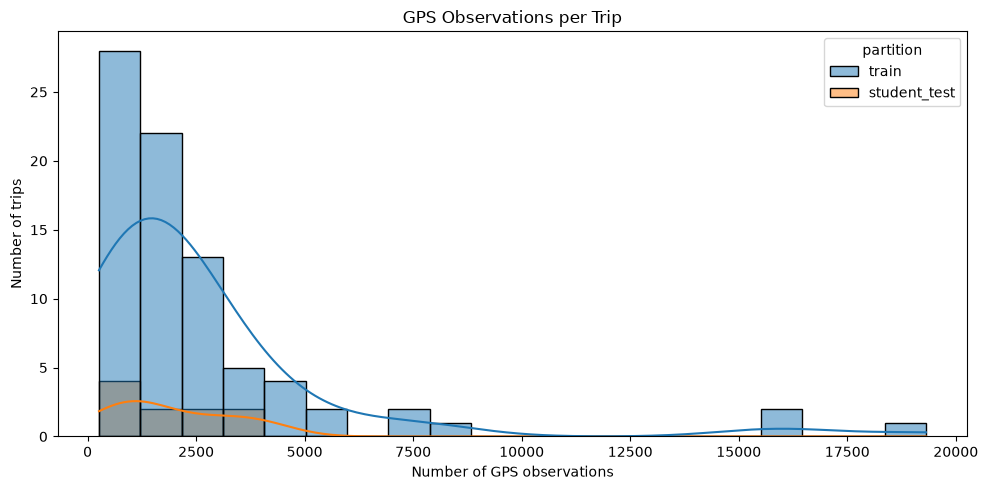

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=gps_summary,
    x="observations",
    hue="partition",
    bins=20,
    kde=True
)

plt.title("GPS Observations per Trip")
plt.xlabel("Number of GPS observations")
plt.ylabel("Number of trips")

plt.tight_layout()
plt.savefig(PLOT_DIR / "gps_observations_distribution.png")
plt.show()


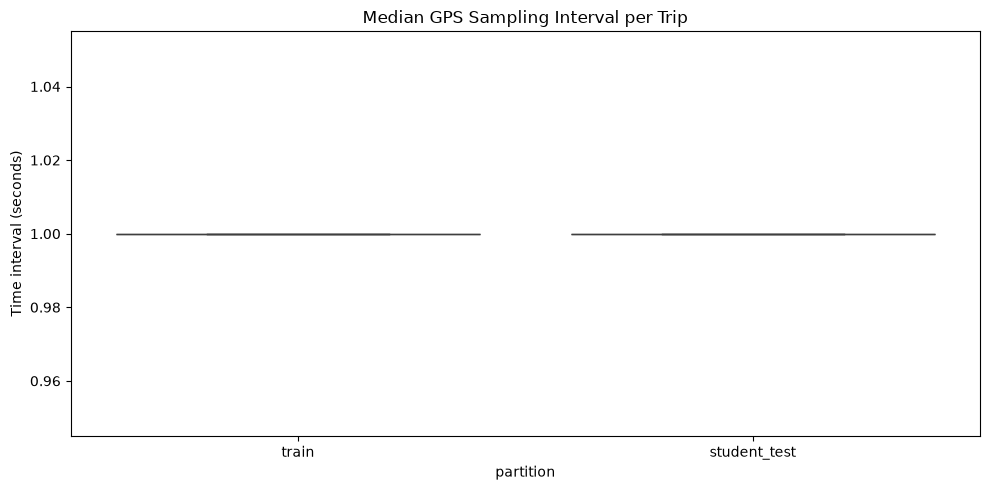

In [13]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=gps_summary,
    x="partition",
    y="median_time_gap_sec"
)

plt.title("Median GPS Sampling Interval per Trip")
plt.ylabel("Time interval (seconds)")

plt.tight_layout()
plt.savefig(PLOT_DIR / "gps_sampling_intervals.png")
plt.show()

In [15]:
# Convert speeds from m/s to km/h
anomaly_report = gps_summary.copy()

anomaly_report["max_speed_kmh"] = (
    anomaly_report["max_speed_mps"] * 3.6
)

anomaly_report["median_speed_kmh"] = (
    anomaly_report["median_speed_mps"] * 3.6
)

# 1. Trips with highest maximum GPS speeds
print("TOP 15 TRIPS BY MAXIMUM SPEED")

display(
    anomaly_report.nlargest(15, "max_speed_mps")[
        [
            "partition",
            "trip_id",
            "observations",
            "large_gaps",
            "max_time_gap_sec",
            "median_speed_kmh",
            "max_speed_kmh"
        ]
    ]
)

# 2. Trips with the most GPS timestamp gaps
print("TOP 15 TRIPS BY TIMESTAMP GAPS")

display(
    anomaly_report.nlargest(15, "large_gaps")[
        [
            "partition",
            "trip_id",
            "observations",
            "large_gaps",
            "max_time_gap_sec",
            "median_time_gap_sec"
        ]
    ]
)

TOP 15 TRIPS BY MAXIMUM SPEED


,partition,trip_id,observations,large_gaps,max_time_gap_sec,median_speed_kmh,max_speed_kmh
62,train,00000079,689,0,1.0,57.043862,648.496895
26,train,00000033,5844,407,3.0,24.819442,511.023287
10,train,00000013,2580,93,8.0,102.452358,509.554412
35,train,00000043,2322,5,230.0,104.436538,473.987835
73,train,00000092,7892,0,1.0,47.656452,305.973667
46,train,00000057,1645,5,13.0,48.518802,301.704892
25,train,00000032,2464,98,41.0,147.492559,299.798693
83,student_test,00000040,2995,0,1.0,63.503876,262.359507
0,train,00000001,1315,25,16.0,148.579767,260.716176
43,train,00000053,1304,5,10.0,81.465912,256.270985


TOP 15 TRIPS BY TIMESTAMP GAPS


,partition,trip_id,observations,large_gaps,max_time_gap_sec,median_time_gap_sec
78,train,00000098,5584,1268,50.0,1.0
64,train,00000081,3224,903,536.0,1.0
61,train,00000078,2909,712,52810.0,1.0
38,train,00000046,1401,529,22.0,1.0
3,train,00000004,1064,491,51.0,1.0
26,train,00000033,5844,407,3.0,1.0
19,train,00000025,1179,361,2.0,1.0
72,train,00000090,536,224,153064.0,1.0
17,train,00000022,474,222,22.0,1.0
87,student_test,00000076,1486,206,32.0,1.0


Timestamp interval statistics:


,count,mean,std,min,25%,50%,75%,max
partition,,,,,,,,
student_test,19150.0,1.057441,1.663988,1.0,1.0,1.0,1.0,210.0
train,208337.0,2.181237,354.852204,1.0,1.0,1.0,1.0,153064.0


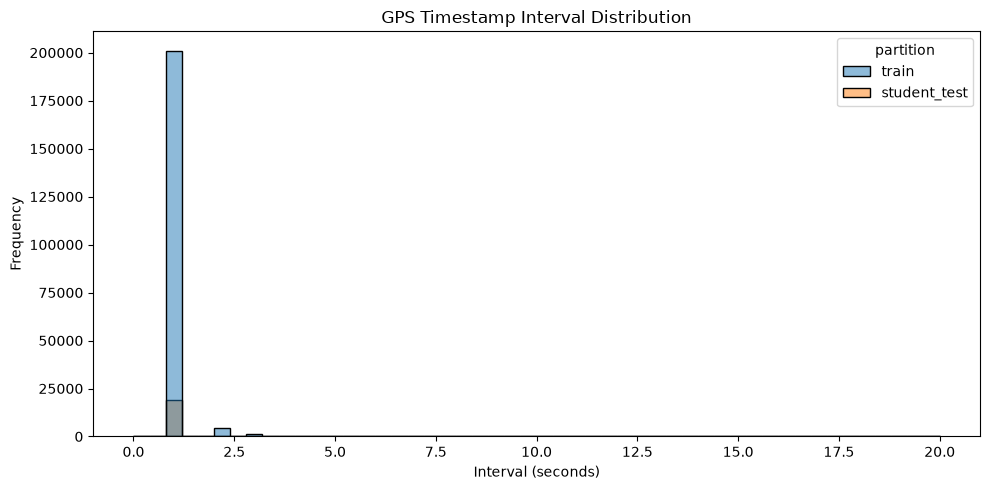

In [16]:
gap_data = []

for partition in ["train", "student_test"]:

    for trip_dir in sorted((DATA_DIR / partition).iterdir()):

        if not trip_dir.is_dir():
            continue

        track = load_track(
            trip_dir / f"{trip_dir.name}.track"
        )

        gaps = track["timestamp"].diff()
        gaps = gaps[gaps > 0]

        gap_data.extend([
            {
                "partition": partition,
                "gap_seconds": gap
            }
            for gap in gaps
        ])

gap_df = pd.DataFrame(gap_data)

print("Timestamp interval statistics:")
display(
    gap_df.groupby("partition")["gap_seconds"].describe()
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=gap_df,
    x="gap_seconds",
    hue="partition",
    bins=50,
    binrange=(0, 20)
)

plt.title("GPS Timestamp Interval Distribution")
plt.xlabel("Interval (seconds)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(PLOT_DIR / "gps_gap_distribution.png")
plt.show()